In [2]:
import scanpy as sc

adata = sc.read_h5ad('../../cellman_paper/sc_benchmarking/TS/store/Lung/human_lung.h5ad')
adata

AnnData object with n_obs × n_vars = 65847 × 60606
    obs: 'donor_id', 'tissue_in_publication', 'anatomical_position', 'method', 'cdna_plate', 'library_plate', 'notes', 'cdna_well', 'assay_ontology_term_id', 'sample_id', 'replicate', '10X_run', 'ambient_removal', 'donor_method', 'donor_assay', 'donor_tissue', 'donor_tissue_assay', 'compartment', 'published_2022', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ercc', 'pct_counts_ercc', '_scvi_batch', '_scvi_labels', 'scvi_leiden_donorassay_full', 'ethnicity_original', 'sample_number', 'suspension_type', 'tissue_type', 'tissue_ontology_term_id', 'disease_ontology_term_id', 'is_primary_data', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'leiden'
    var: 'ensembl_id', 'genome', 'mt', 'ercc', 'n_cells_by_counts', 'mean_counts', 'pct_d

/annotate-mode Annotate the h5ad file below using annotate-expert agent.

- input : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/cellman_paper/sc_benchmarking/TS/store/Lung/human_lung.h5ad
- out : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/cellman_paper/sc_benchmarking/TS/store/Lung
- virtual env : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv 
- use 5090 GPU on device '1'
- cluster column : leiden 
- NOTE : use X, not raw.X.

In [2]:
import scanpy as sc
adata_annotated = sc.read_h5ad('/bce/groups/pnucolab/analysis/l202255179/UNNAMED/cellman_paper/sc_benchmarking/TS/store/Lung/annotation_out/human_lung_annotated.h5ad')
adata_annotated

AnnData object with n_obs × n_vars = 65847 × 60606
    obs: 'donor_id', 'tissue_in_publication', 'anatomical_position', 'method', 'cdna_plate', 'library_plate', 'notes', 'cdna_well', 'assay_ontology_term_id', 'sample_id', 'replicate', '10X_run', 'ambient_removal', 'donor_method', 'donor_assay', 'donor_tissue', 'donor_tissue_assay', 'compartment', 'published_2022', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ercc', 'pct_counts_ercc', '_scvi_batch', '_scvi_labels', 'scvi_leiden_donorassay_full', 'ethnicity_original', 'sample_number', 'suspension_type', 'tissue_type', 'tissue_ontology_term_id', 'disease_ontology_term_id', 'is_primary_data', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'leiden', 'cellman_annotation'
    var: 'ensembl_id', 'genome', 'mt', 'ercc', 'n_cells_by_counts',

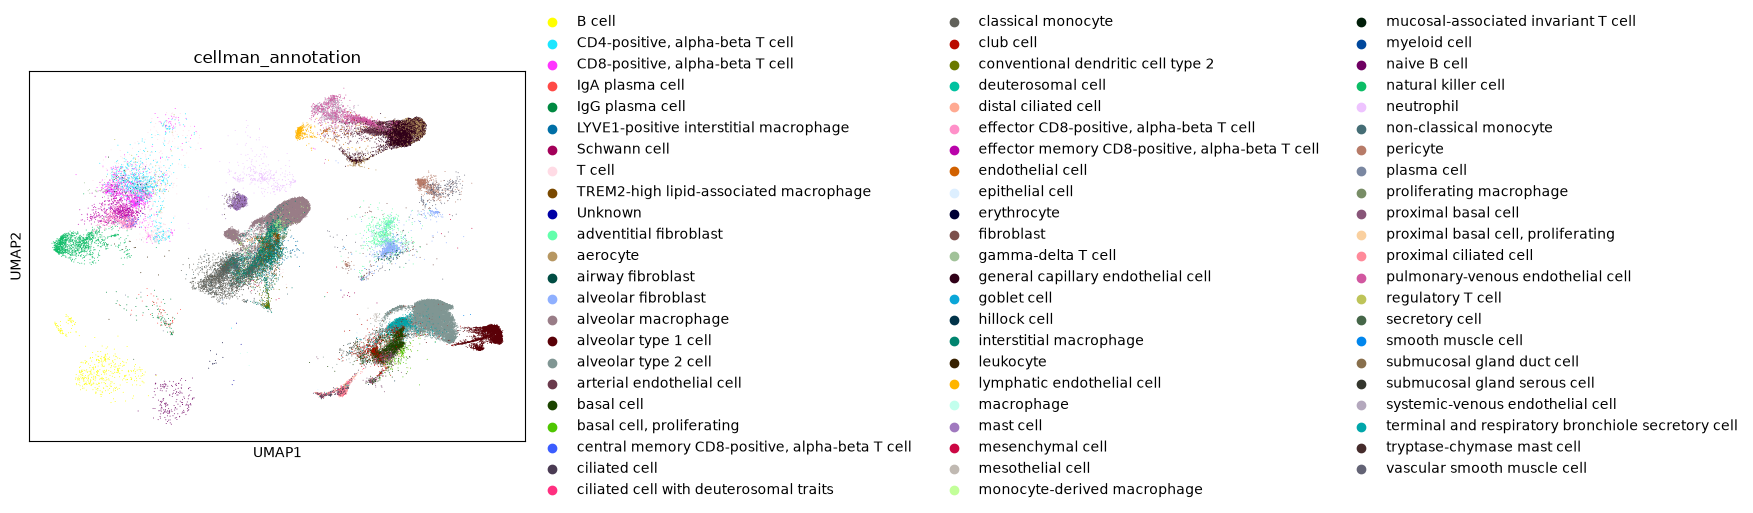

In [8]:
sc.pl.umap(adata_annotated, color='cellman_annotation')

In [5]:
adata_annotated.obs['cellman_annotation'].cat.categories

Index(['B cell', 'CD4-positive, alpha-beta T cell',
       'CD8-positive, alpha-beta T cell', 'IgA plasma cell', 'IgG plasma cell',
       'LYVE1-positive interstitial macrophage', 'Schwann cell', 'T cell',
       'TREM2-high lipid-associated macrophage', 'Unknown',
       'adventitial fibroblast', 'aerocyte', 'airway fibroblast',
       'alveolar fibroblast', 'alveolar macrophage', 'alveolar type 1 cell',
       'alveolar type 2 cell', 'arterial endothelial cell', 'basal cell',
       'basal cell, proliferating',
       'central memory CD8-positive, alpha-beta T cell', 'ciliated cell',
       'ciliated cell with deuterosomal traits', 'classical monocyte',
       'club cell', 'conventional dendritic cell type 2', 'deuterosomal cell',
       'distal ciliated cell', 'effector CD8-positive, alpha-beta T cell',
       'effector memory CD8-positive, alpha-beta T cell', 'endothelial cell',
       'epithelial cell', 'erythrocyte', 'fibroblast', 'gamma-delta T cell',
       'general capillary 

In [6]:
endo = ['general capillary endothelial cell', 'aerocyte', 'pulmonary-venous endothelial cell',
        'arterial endothelial cell', 'systemic-venous endothelial cell', 'lymphatic endothelial cell',
        'endothelial cell']
Tcell = ['T cell', 'CD4-positive, alpha-beta T cell', 'CD8-positive, alpha-beta T cell',
         'effector memory CD8-positive, alpha-beta T cell', 'effector CD8-positive, alpha-beta T cell',
         'gamma-delta T cell', 'central memory CD8-positive, alpha-beta T cell',
         'mucosal-associated invariant T cell', 'regulatory T cell'
         ]
Bcell = ['B cell', 'naive B cell']
plasma = ['IgG plasma cell', 'IgA plasma cell', 'plasma cell']
nk = ['natural killer cell']

[slim] human/lung from http://192.168.101.31:8088: 265 terms


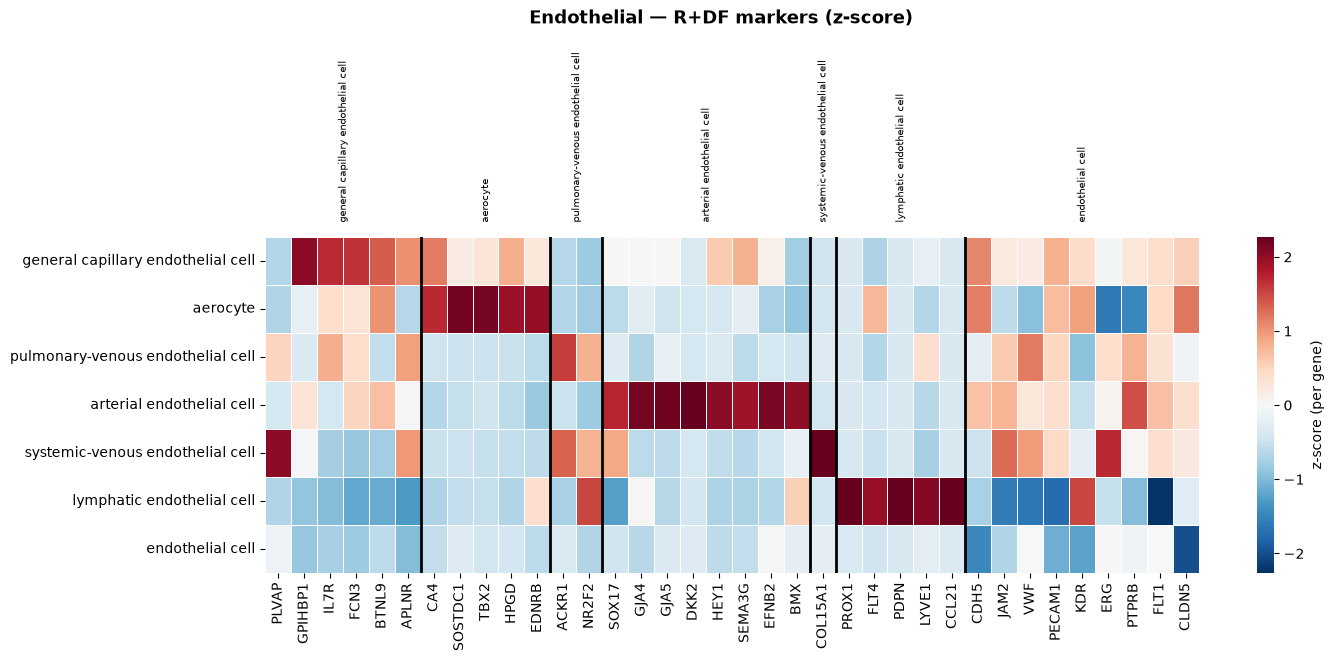

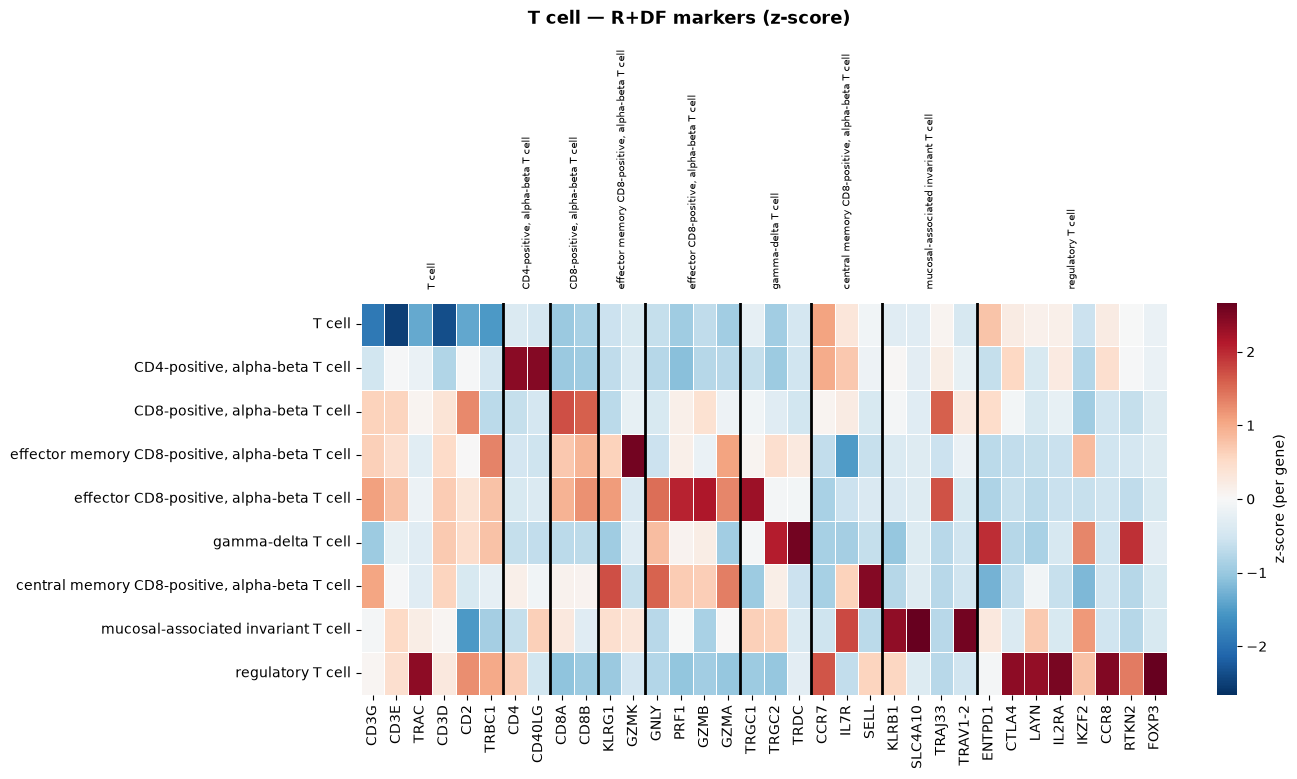

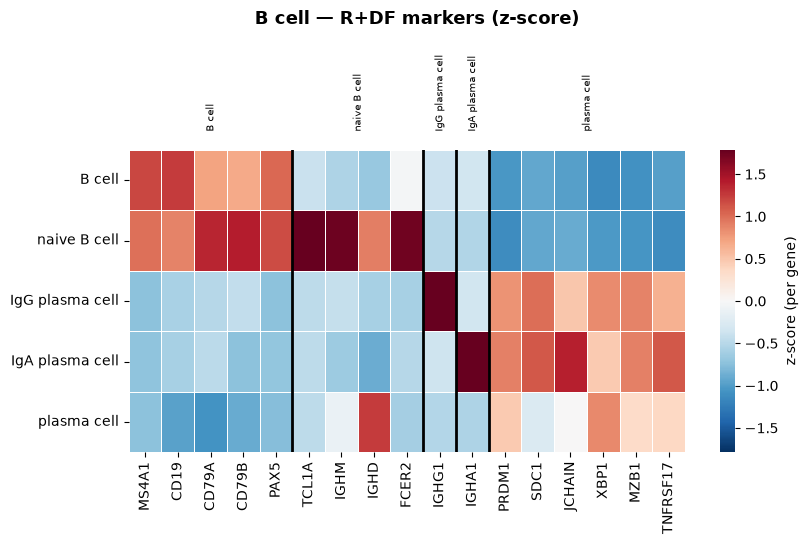

In [3]:
import os, requests, numpy as np, pandas as pd, scanpy as sc, scipy.sparse as spr
import matplotlib.pyplot as plt, seaborn as sns

# ── config ──────────────────────────────────────────────────────────────────
H5AD    = "/bce/groups/pnucolab/analysis/l202255179/UNNAMED/cellman_paper/sc_benchmarking/TS/store/Lung/annotation_out/human_lung_annotated.h5ad"
SERVER  = os.environ.get("CELLONTO_SERVER_URL", "https://cellman.pnucolab.com")
SPECIES, ORGAN = "human", "lung"      # <-- 이 데이터가 annotate된 wing. (지시엔 "mouse kidney"였으나
                                      #     리스트가 폐 세포라 human/lung 이어야 마커가 잡힙니다.)
ANNCOL  = "cellman_annotation"
MAX_CELLS_PER_TYPE = 3000             # 층화 서브샘플 (큰 데이터 속도)

# ── KG slim-index 한 번만 서빙 (Required + Defining 마커) ─────────────────────
def _fetch_slim(sp, og):
    for base in dict.fromkeys([SERVER, "https://cellman.pnucolab.com"]):
        try:
            j = requests.get(f"{base.rstrip('/')}/module/{sp}/{og}/slim-index", timeout=30).json()
            if isinstance(j, dict) and "terms" in j:
                print(f"[slim] {sp}/{og} from {base}: {j.get('n_terms')} terms")
                return j
        except Exception:
            pass
    raise RuntimeError("slim-index fetch failed")

slim = _fetch_slim(SPECIES, ORGAN)
byL  = {t.get("L"): t for t in slim["terms"].values()}

def markers_RD(term):                 # Required ∪ Defining 만 (Supporting/Negative 제외)
    g = []
    for s in ("R", "DF"):
        g += (term.get(s) or [])
    return list(dict.fromkeys(g))      # 순서 유지 dedup

# ── 리스트 하나 → heatmap 하나 ────────────────────────────────────────────────
def plot_marker_heatmap(celltypes, adata, name="", max_cells_per_type=MAX_CELLS_PER_TYPE):
    """y = celltypes, x = 각 celltype의 R+DF 마커(블록), 값 = 유전자별 z-score (red 高 / blue 低)."""
    # KG 마커 심볼 → 데이터 var_name (case-insensitive)
    var_upper = {}
    for v in map(str, adata.var_names):
        var_upper.setdefault(v.upper(), v)
    def in_panel(genes):
        out, seen = [], set()
        for g in genes:
            v = var_upper.get(str(g).upper())
            if v is not None and v not in seen:
                seen.add(v); out.append(v)
        return out

    # celltype별 마커 블록 (블록 간 유전자 중복은 앞 celltype 우선으로 dedup)
    present = set(adata.obs[ANNCOL].astype(str).unique())
    used, blocks, kept = set(), {}, []
    for ct in celltypes:
        if ct not in byL:
            print(f"[warn] {ct!r} not in {SPECIES}/{ORGAN} KG — skipped"); continue
        if ct not in present:
            print(f"[warn] {ct!r} not in adata labels — skipped"); continue
        gs = [g for g in in_panel(markers_RD(byL[ct])) if not (g in used or used.add(g))]
        if not gs:
            print(f"[warn] {ct!r} has no R/DF markers in the panel — skipped"); continue
        blocks[ct] = gs; kept.append(ct)
    if not kept:
        print(f"[{name}] nothing to plot"); return

    genes = [g for gs in blocks.values() for g in gs]

    # 이 celltype들의 셀만 골라 층화 서브샘플
    lab = adata.obs[ANNCOL].astype(str)
    sub = adata[lab.isin(kept)].copy()
    lv, rng, keep = sub.obs[ANNCOL].astype(str).values, np.random.default_rng(0), []
    for ct in kept:
        ci = np.flatnonzero(lv == ct)
        keep.append(rng.choice(ci, max_cells_per_type, replace=False) if len(ci) > max_cells_per_type else ci)
    sub = sub[np.sort(np.concatenate(keep))].copy()

    # celltype별 평균 발현 → 유전자별 z-score
    X = sub[:, genes].X
    X = X.toarray() if spr.issparse(X) else np.asarray(X)
    M  = (pd.DataFrame(X, columns=genes, index=sub.obs[ANNCOL].astype(str).values)
            .groupby(level=0).mean().loc[kept, genes])     # celltypes x genes
    Mz = (M - M.mean(0)) / M.std(0).replace(0, 1)          # per-gene z-score
    vmax = float(np.nanmax(np.abs(Mz.values))) or 1.0      # 대칭 발산 범위

    fig, ax = plt.subplots(figsize=(0.32 * len(genes) + 3, 0.6 * len(kept) + 2.5))
    sns.heatmap(Mz, cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax, ax=ax,
                linewidths=0.5, linecolor="white", cbar_kws=dict(label="z-score (per gene)"))
    bounds = np.cumsum([len(v) for v in blocks.values()]); starts = np.concatenate([[0], bounds[:-1]])
    for x in bounds[:-1]:                                   # 블록 간 검은 세로 구분선
        ax.axvline(x, color="k", lw=2)
    for ct, s0, e0 in zip(kept, starts, bounds):           # 각 블록 위에 celltype 이름
        ax.text((s0 + e0) / 2, -0.3, ct, ha="center", va="bottom", rotation=90, fontsize=7)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.set_xlabel(""); ax.set_ylabel("")
    fig.suptitle(f"{name} — R+DF markers (z-score)", fontsize=13, fontweight="bold")
    fig.tight_layout(); plt.show()

# ── 실행 ──────────────────────────────────────────────────────────────────────
adata = sc.read_h5ad(H5AD)            # 또는 노트북에 이미 있으면: adata = adata_annotated

endo = ['general capillary endothelial cell', 'aerocyte', 'pulmonary-venous endothelial cell',
        'arterial endothelial cell', 'systemic-venous endothelial cell', 'lymphatic endothelial cell',
        'endothelial cell']
Tcell = ['T cell', 'CD4-positive, alpha-beta T cell', 'CD8-positive, alpha-beta T cell',
         'effector memory CD8-positive, alpha-beta T cell', 'effector CD8-positive, alpha-beta T cell',
         'gamma-delta T cell', 'central memory CD8-positive, alpha-beta T cell',
         'mucosal-associated invariant T cell', 'regulatory T cell']
Bcell = ['B cell', 'naive B cell', 'IgG plasma cell', 'IgA plasma cell', 'plasma cell']

for lst, nm in [(endo, "Endothelial"), (Tcell, "T cell"), (Bcell, "B cell")]:
    plot_marker_heatmap(lst, adata, name=nm)


In [ ]:
markers = {ct: in_panel(markers_RD(byL[ct])) for ct in endo if ct in byL}


In [3]:
ref = sc.read_h5ad('/bce/groups/pnucolab/analysis/l202255179/UNNAMED/test/scRNA-seq/tabula_sapiens/sub_v2/Lung.h5ad')
ref

AnnData object with n_obs × n_vars = 65847 × 60606
    obs: 'donor_id', 'tissue_in_publication', 'anatomical_position', 'method', 'cdna_plate', 'library_plate', 'notes', 'cdna_well', 'assay_ontology_term_id', 'sample_id', 'replicate', '10X_run', 'ambient_removal', 'donor_method', 'donor_assay', 'donor_tissue', 'donor_tissue_assay', 'cell_type_ontology_term_id', 'compartment', 'broad_cell_class', 'free_annotation', 'manually_annotated', 'published_2022', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ercc', 'pct_counts_ercc', '_scvi_batch', '_scvi_labels', 'scvi_leiden_donorassay_full', 'ethnicity_original', 'sample_number', 'suspension_type', 'tissue_type', 'tissue_ontology_term_id', 'disease_ontology_term_id', 'is_primary_data', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joi

In [11]:
ref.uns['cell_type_colors'] = adata_annotated.uns['cellman_annotation_colors'][:len(ref.uns['cell_type_colors'])]

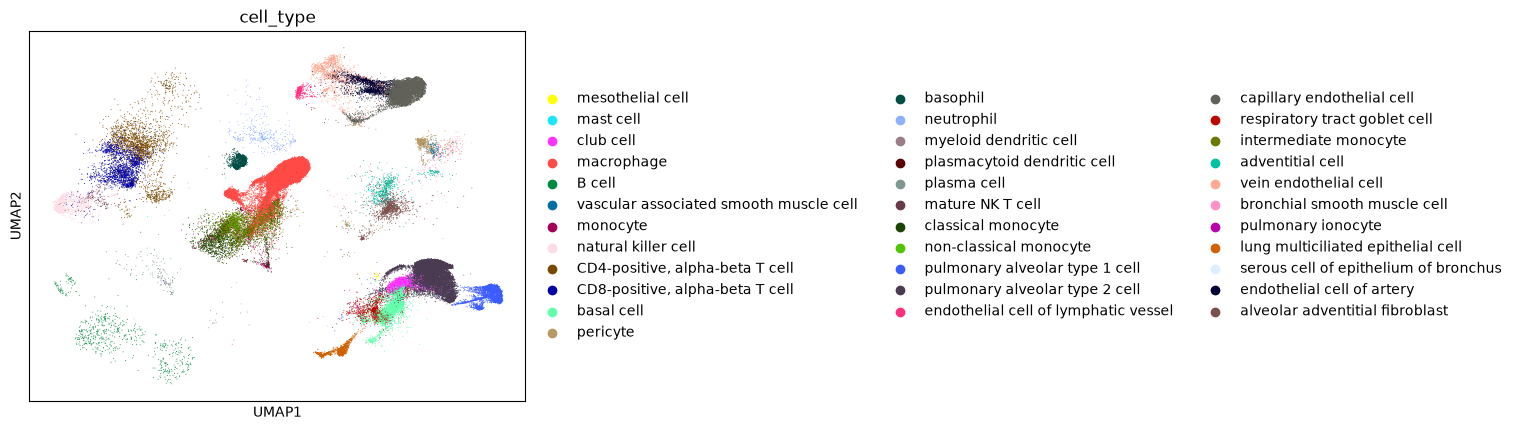

In [12]:
sc.pl.umap(ref, color='cell_type')